In [23]:
%run general.ipynb
%matplotlib inline
RESULTS_DIR = '../results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Output directory: {RESULTS_DIR}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2026-05-18 16:13:42 WARNING These have metadata but do not have data - dropped (415): {'BLANK8.10E', 'H1.skin.TE.09.14.15.11a.glass.5', 'H3.skin.TE.09.14.15.3p.glass.3', 'surface.ctrl.TE.09.14.15.4p.plastic.4', 'surface.ctrl.TE.09.14.15.11a.metal.2', 'H1.skin.TE.09.14.15.1p.metal.3', 'H9.surface.10x.TE.03.18.16.ceramic.2', 'H2.skin.TE.09.14.15.11a.metal.2', 'BLANK8.9F', 'BLANK8.5D', 'BLANK8.9A', 'BLANK.4.C10', 'H2.skin.TE.09.14.15.1p.metal.2', 'H3.skin.TE.09.14.15.1p.glass.4', 'H4.skin.TE.09.14.15.1p.metal.5', 'H5.skin.TE.09.14.15.3p.metal.5', 'BLANK8.11B', 'BLANK7.7D', 'H2.skin.TE.09.14.15.11a.metal.1', 'H5.skin.TE.09.14.15.11a.glass.4', 'surface.ctrl.TE.09.14.15.4p.glass.5', 'BLANK13.1.1F', 'H2.skin.TE.09.14.15.1p.glass.5', 'surface.ctrl.TE.05.18.16.plastic.1', 'H2.skin.TE.09.14.15.3p.metal.2', 'surface.ctrl.9.11.17.plastic.1sec.1', 'BLANK8.5G', 'BLANK12.A11', 'BLANK10.10A', 'surface.ctrl.TE.09.14

### Part 3: **Persistence** Analysis of Skin Microbiome

This experiment tests how long microbial signals left by individuals persist on surfaces.

In [24]:
exp_persistence_filtered = exp
metadata_persistence = exp_persistence_filtered.sample_metadata

In [25]:
persistence_touch_meta = metadata_persistence.query('experiment_category=="persistence" & sample_type=="surface_touched"')
persistence_skin2_meta = metadata_persistence.query('experiment_category=="persistence" & experiment=="exp201709" & sample_type=="skin"')
persistence_skin1_meta = metadata_persistence.query('experiment=="exp201603" & sample_type=="skin"')

persistence_sample_ids = persistence_touch_meta.index.tolist() + persistence_skin1_meta.index.tolist() + persistence_skin2_meta.index.tolist()

hosts_persistence_touch = set(persistence_touch_meta.individual)
hosts_persistence_skin1 = set(persistence_skin1_meta['individual'])
hosts_persistence_skin2 = set(persistence_skin2_meta['individual'])
common_hosts_persistence = list(hosts_persistence_touch & (hosts_persistence_skin1 | hosts_persistence_skin2))

print(f"Number of common hosts for persistence experiment: {len(common_hosts_persistence)}")
common_hosts_persistence

Number of common hosts for persistence experiment: 24


['H55',
 'H5',
 'H56',
 'H53',
 'H34',
 'H17',
 'H51',
 'H33',
 'H11',
 'H14',
 'H49',
 'H12',
 'H29',
 'H15',
 'H16',
 'H1',
 'H52',
 'H13',
 'H2',
 'H50',
 'H10',
 'H54',
 'H4',
 'H18']

In [26]:
exp_persistence = (exp_persistence_filtered.filter_ids(persistence_sample_ids, axis=0).filter_samples('individual', common_hosts_persistence))
exp_persistence

AmpliconExperiment ("reference-hit.2026.biom") with 301 samples, 10511 features

In [27]:
metadata_persistence = exp_persistence.sample_metadata

In [28]:
exp_persistence.filter_samples('sample_type', 'skin').sample_metadata['individual'].value_counts()

individual
H2     10
H15    10
H5     10
H13    10
H10     8
H33     5
H54     5
H34     5
H49     5
H55     5
H29     5
H53     5
H51     5
H56     5
H11     5
H16     5
H12     5
H1      5
H18     5
H14     5
H17     5
H4      5
H52     5
H50     4
Name: count, dtype: int64

In [29]:
train_set_persistence = (exp_persistence.filter_samples('sample_type', 'skin')
                                  .filter_sample_categories('individual', min_samples=4)
                                  .filter_by_metadata('_calour_original_abundance', select=lambda i: i > 500)
                                  .filter_abundance(0, strict=True)
                                 )
train_set_persistence

AmpliconExperiment ("reference-hit.2026.biom") with 136 samples, 4381 features

In [30]:
train_set_persistence.sample_metadata.pivot_table(values='_sample_id',
                                                      columns='experiment',
                                                      index='individual',
                                                      aggfunc=len)

experiment,exp201603,exp201709
individual,,
H1,5.0,NaN
H10,4.0,3.0
H11,5.0,NaN
H12,5.0,NaN
H13,5.0,5.0
H14,3.0,NaN
H15,5.0,5.0
H16,5.0,NaN
H17,5.0,NaN


In [31]:
test_set_persistence = (exp_persistence.filter_samples('sample_type', 'surface_touched')
                                .filter_samples('individual', train_set_persistence.sample_metadata['individual'].unique().tolist())
                                .filter_ids(train_set_persistence.feature_metadata.index, axis=1)
                                .filter_by_metadata('_calour_original_abundance', select=lambda i: i > 200))

test_set_persistence.sample_metadata['persistence_time_sec'] = test_set_persistence.sample_metadata['persistence_time_sec'].astype(int)
test_set_persistence = test_set_persistence.sort_samples('persistence_time_sec').sort_samples('individual').sort_samples('surface_type')
test_set_persistence.sample_metadata.pivot_table(values='sample_date', index='individual', columns=['sample_type', 'surface_type'], aggfunc=len)

sample_type  surface_touched        
surface_type         ceramic plastic
individual                          
H1                       1.0     4.0
H10                      NaN     4.0
H11                      1.0     4.0
H12                      4.0     4.0
H13                      3.0     8.0
H14                      4.0     4.0
H15                      4.0     8.0
H16                      4.0     4.0
H17                      3.0     3.0
H18                      3.0     4.0
H2                       4.0     8.0
H29                      NaN     4.0
H33                      NaN     4.0
H34                      NaN     4.0
H4                       4.0     4.0
H49                      NaN     4.0
H5                       4.0     6.0
H50                      NaN     4.0
H51                      NaN     4.0
H52                      NaN     4.0
H53                      NaN     4.0
H54                      NaN     4.0
H55                      NaN     4.0
H56                      NaN     4.0

In [32]:
X_train_persistence = train_set_persistence.data
y_train_persistence = train_set_persistence.sample_metadata.individual

In [33]:
grid_search_persistence = make_rf_grid_search()


In [34]:
#Load or Run Grid Search ---
saved_model_path_persistence = os.path.join(RESULTS_DIR, 'persistence-combined.pkl.bz2')
best_model_persistence = load_or_fit_model(
    grid_search_persistence,
    saved_model_path_persistence,
    train_set_persistence.data,
    train_set_persistence.sample_metadata.individual
)

Loading pre-trained model from ../results/persistence-combined.pkl.bz2...


In [35]:
jk_cache_path = os.path.join(RESULTS_DIR, 'persistence-jackknife.pkl.bz2')

jackknife_results4 = compute_persistence_jackknife(
    model=best_model_persistence,
    test_exp=test_set_persistence,
    cache_path=jk_cache_path,
    max_N=20,
    progress_every=50,
)

jk4_acc = jackknife_results4['jk4_acc'] 
materials = jackknife_results4['materials']
exp1_times = jackknife_results4['exp1_times']
exp2_times = jackknife_results4['exp2_times']
max_N = jackknife_results4['max_N']


Loading cached jackknife results from: ../results/persistence-jackknife.pkl.bz2


In [36]:
def plot_topn_persistence(exp_i, mat_i, time_labels, exp_name, mat_name, filename_suffix, title):
    fig_path = os.path.join(RESULTS_DIR, f'top-N_{filename_suffix}.pdf')
    plot_persistence_topn_jackknife(
        jk_topn=jk4_acc,
        sample_metadata=test_set_persistence.sample_metadata,
        exp_i=exp_i,
        mat_i=mat_i,
        time_labels=time_labels,
        mat_name=mat_name,
        save_path=fig_path,
        title=title,
        show=True,
    )
    print(f"Saved: {fig_path}")



--- Generating Plot 1: exp1 (exp201603) - plastic ---


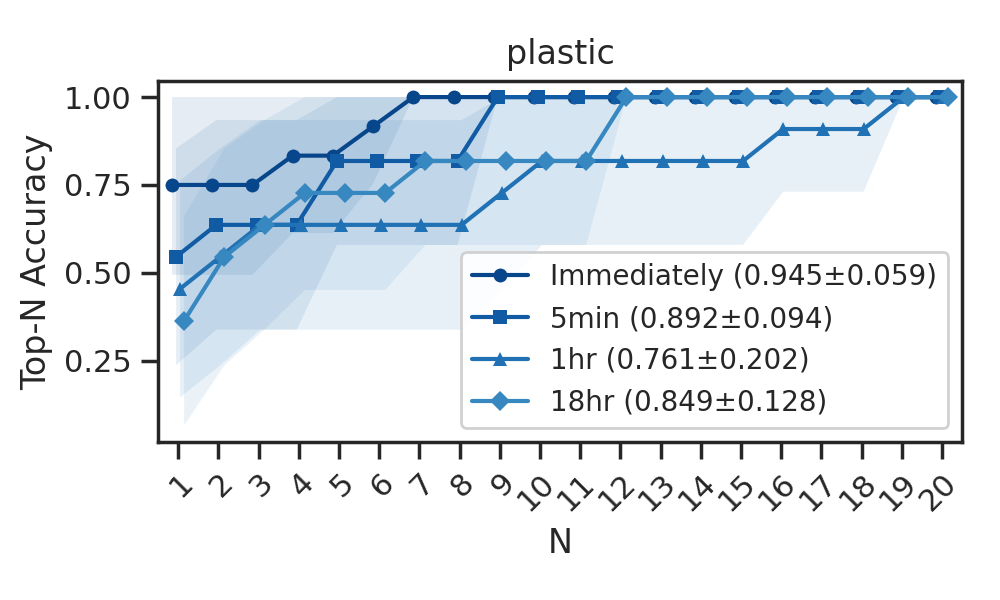

Saved: ../results/top-N_exp1_plastic.pdf

--- Generating Plot 2: exp2 (exp201709) - plastic ---


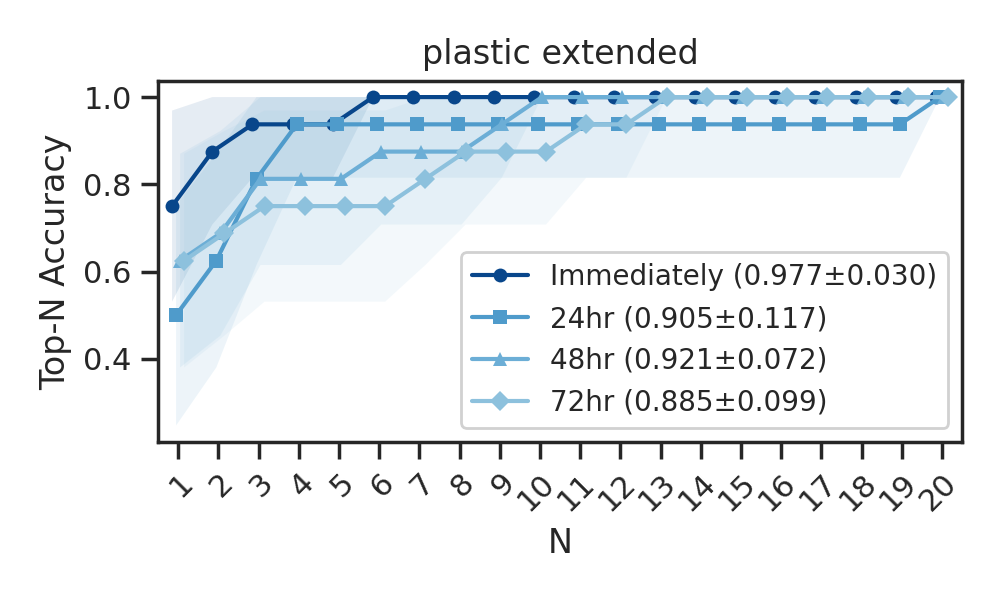

Saved: ../results/top-N_exp2_plastic.pdf

--- Generating Plot 3: exp1 (exp201603) - ceramic ---


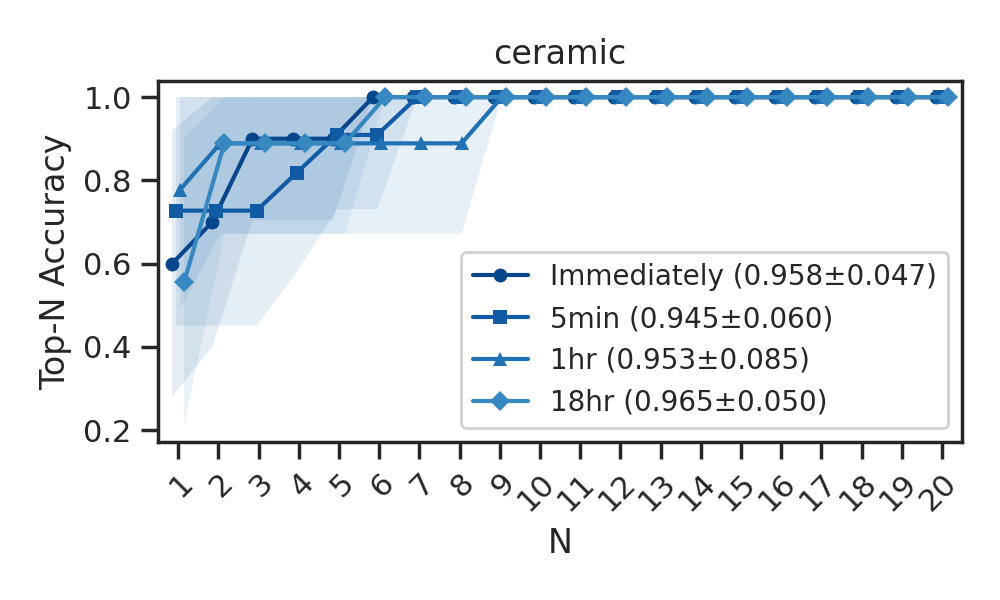

Saved: ../results/top-N_exp1_ceramic.pdf


In [37]:
# View 1: exp1 - plastic
print("\n--- Generating Plot 1: exp1 (exp201603) - plastic ---")
plot_topn_persistence(
    exp_i=0, mat_i=0, time_labels=exp1_times, title = "plastic",
    exp_name='exp1 (2016)', mat_name='plastic', filename_suffix='exp1_plastic'
)

# View 2: exp2 - plastic
print("\n--- Generating Plot 2: exp2 (exp201709) - plastic ---")
plot_topn_persistence(
    exp_i=1, mat_i=0, time_labels=exp2_times, title = "plastic extended",
    exp_name='exp2 (2017)', mat_name='plastic', filename_suffix='exp2_plastic'
)

# View 3: exp1 - ceramic
print("\n--- Generating Plot 3: exp1 (exp201603) - ceramic ---")
plot_topn_persistence(
    exp_i=0, mat_i=1, time_labels=exp1_times, title = "ceramic",
    exp_name='exp1 (2016)', mat_name='ceramic', filename_suffix='exp1_ceramic'
)

In [38]:
import pandas as pd
import numpy as np
import os
from statsmodels.stats.multitest import multipletests

np.random.seed(123) 

base_path = "../"

In [39]:
# =================================================================
# =================================================================
import glob
import seaborn as sns
from plotnine import *

TIME_LEVELS = ["immediately", "5min", "1hr", "18hr", "24hr", "48hr", "72hr"]
TIME_RECODE = {
    1: "immediately", 300: "5min", 3600: "1hr", 64800: "18hr", 86400: "24hr", 172800: "48hr", 259200: "72hr",
    1.0: "immediately", 300.0: "5min", 3600.0: "1hr", 64800.0: "18hr", 86400.0: "24hr", 172800.0: "48hr", 259200.0: "72hr",
}
PLOT_GROUP_MAP = {'plastic_2016': 'plastic_exp1', 'ceramic_2016': 'ceramic', 'plastic_2017': 'plastic_exp2'}
TARGET_INDIVIDUALS = [
    "H54", "H55", "H50", "H18", "H10", "H14", "H11", "H51", "H5", "H29", "H49", "H53",
    "H4", "H33", "H52", "H34", "H13", "H15", "H56", "H1", "H17", "H2", "H12", "H16",
]
PLOT_GROUP_LEVELS = ["ceramic", "plastic_exp1", "plastic_exp2"]
COMPARISON_LEVELS = ["Skin_vs_Skin_Across", "Skin_vs_Skin_Within", "immediately", "5min", "1hr", "18hr", "24hr", "48hr", "72hr"]

def tidy_distance_matrix(df):
    mask = np.triu(np.ones(df.shape), k=1).astype(bool)
    stacked = df.where(mask).stack().reset_index()
    stacked.columns = ['sample1', 'sample2', 'distance']
    swap_mask = stacked['sample1'] > stacked['sample2']
    stacked.loc[swap_mask, ['sample1', 'sample2']] = stacked.loc[swap_mask, ['sample2', 'sample1']].values
    return stacked

def prepare_persistence_beta_metadata(metadata_df):
    meta = metadata_df.copy()
    meta.index = meta.index.astype(str).str.strip()
    for col in ['sample_type', 'surface_type', 'individual']:
        if col in meta.columns:
            meta[col] = meta[col].astype(str).str.strip()
    meta['persistence_time_sec'] = pd.to_numeric(meta['persistence_time_sec'], errors='coerce').replace(TIME_RECODE)
    meta['plot_category'] = np.where(
        meta['sample_type'] == 'skin',
        'Skin',
        np.where((meta['sample_type'] == 'surface_touched') & meta['surface_type'].notna(), meta['surface_type'] + '_' + meta['persistence_time_sec'].astype(str), 'Other'),
    )
    meta['Time'] = np.where(meta['sample_type'] == 'skin', 'Skin', meta['persistence_time_sec'])
    meta['Time'] = pd.Categorical(meta['Time'], categories=['Skin'] + TIME_LEVELS, ordered=True)
    return meta.loc[meta['plot_category'] != 'Other'].copy()

def load_clean_dist(base_path, metric_name):
    pattern = os.path.join(base_path, f"data/extracted_qza/{metric_name}_distance_matrix/*/data/distance-matrix.tsv")
    matches = glob.glob(pattern)
    if not matches:
        raise FileNotFoundError(f"No distance-matrix.tsv found for {metric_name}")
    df = pd.read_csv(matches[0], sep="	", index_col=0)
    df.index = df.index.astype(str).str.strip()
    df.columns = df.columns.astype(str).str.strip()
    return df

def build_pairwise_distance_table(distance_matrices, metadata_df):
    common_ids = sorted(set(metadata_df.index).intersection(*[set(mat.index) for mat in distance_matrices.values()]))
    meta = metadata_df.loc[common_ids].copy()
    combined = pd.concat([tidy_distance_matrix(mat).assign(distance_type=name) for name, mat in distance_matrices.items()], ignore_index=True)
    combined = combined[(combined['sample1'] < combined['sample2']) & combined['sample1'].isin(common_ids) & combined['sample2'].isin(common_ids)]
    meta_for_join = meta[['sample_type', 'year', 'surface_type', 'persistence_time_sec', 'individual']].rename_axis('sample_id').reset_index()
    rename_templates = {
        'sample_type': '{prefix}_type', 'year': '{prefix}_year', 'surface_type': '{prefix}_surface',
        'persistence_time_sec': '{prefix}_time', 'individual': 'individual{idx}',
    }
    merged = combined.copy()
    for idx, sample_col in enumerate(['sample1', 'sample2'], start=1):
        prefix = f'sample{idx}'
        merged = merged.merge(meta_for_join, left_on=sample_col, right_on='sample_id', how='left').drop(columns=['sample_id'])
        merged = merged.rename(columns={k: v.format(prefix=prefix, idx=idx) for k, v in rename_templates.items()})
    return merged, meta, common_ids

def build_persistence_plot_data(final_df_all):
    skin_surface = final_df_all[
        (((final_df_all['sample1_type'] == 'skin') & (final_df_all['sample2_type'] == 'surface_touched')) | ((final_df_all['sample2_type'] == 'skin') & (final_df_all['sample1_type'] == 'surface_touched')))
        & (final_df_all['sample1_year'] == final_df_all['sample2_year'])
        & (final_df_all['individual1'] == final_df_all['individual2'])
    ].copy()
    skin_surface['surface'] = np.where(skin_surface['sample1_type'] == 'surface_touched', skin_surface['sample1_surface'], skin_surface['sample2_surface'])
    skin_surface['time'] = np.where(skin_surface['sample1_type'] == 'surface_touched', skin_surface['sample1_time'], skin_surface['sample2_time'])
    skin_surface['plot_group'] = (skin_surface['surface'].astype(str) + '_' + skin_surface['sample1_year'].astype(float).astype(int).astype(str)).replace(PLOT_GROUP_MAP)
    skin_surface['comparison_group'] = skin_surface['time'].astype(str)

    same_year_skin = final_df_all[
        (final_df_all['sample1_type'] == 'skin') & (final_df_all['sample2_type'] == 'skin')
        & (final_df_all['sample1_year'] == final_df_all['sample2_year'])
        & final_df_all['individual1'].isin(TARGET_INDIVIDUALS) & final_df_all['individual2'].isin(TARGET_INDIVIDUALS)
    ].copy()
    within = same_year_skin[same_year_skin['individual1'] == same_year_skin['individual2']].copy()
    within['comparison_group'] = 'Skin_vs_Skin_Within'
    across = same_year_skin[same_year_skin['individual1'] != same_year_skin['individual2']].copy()
    across['comparison_group'] = 'Skin_vs_Skin_Across'
    skin_skin = pd.concat([within, across], ignore_index=True)
    expanded = pd.concat([
        skin_skin[skin_skin['sample1_year'] == 2016.0].assign(plot_group='ceramic'),
        skin_skin[skin_skin['sample1_year'] == 2016.0].assign(plot_group='plastic_exp1'),
        skin_skin[skin_skin['sample1_year'] == 2017.0].assign(plot_group='plastic_exp2'),
    ], ignore_index=True)
    plot_data = pd.concat([skin_surface, expanded], ignore_index=True)
    plot_data['plot_group'] = pd.Categorical(plot_data['plot_group'], categories=PLOT_GROUP_LEVELS, ordered=True)
    plot_data['comparison_group'] = pd.Categorical(plot_data['comparison_group'], categories=COMPARISON_LEVELS, ordered=True)
    return plot_data.dropna(subset=['plot_group', 'comparison_group'])

def perm_test_by_group(df, grp1, grp2, val_col='distance', perms=999):
    vals1 = df.loc[df['group'] == grp1, val_col].dropna().values
    vals2 = df.loc[df['group'] == grp2, val_col].dropna().values
    if len(vals1) == 0 or len(vals2) == 0:
        return {'group1': grp1, 'group2': grp2, 'p_value_raw': np.nan}
    obs = np.mean(vals1) - np.mean(vals2)
    comb = np.concatenate([vals1, vals2])
    n1 = len(vals1)
    diffs = [np.mean(shuffled[:n1]) - np.mean(shuffled[n1:]) for shuffled in (np.random.permutation(comb) for _ in range(perms))]
    p = (np.sum(np.abs(diffs) >= np.abs(obs)) + 1) / (perms + 1)
    return {'group1': grp1, 'group2': grp2, 'p_value_raw': p}

def compute_groupwise_stats(subset_plot_data, perms=999):
    stats_rows = []
    for plot_group, group_df in subset_plot_data.groupby('plot_group', observed=True):
        test_df = group_df.rename(columns={'comparison_group': 'group'})
        groups = test_df['group'].dropna().unique().tolist()
        pairs = [(g, 'immediately') for g in groups if g not in ['immediately', 'Skin_vs_Skin_Within', 'Skin_vs_Skin_Across']] + [(g, 'Skin_vs_Skin_Across') for g in groups if g not in ['Skin_vs_Skin_Across', 'Skin_vs_Skin_Within']]
        stats_rows.extend([{**perm_test_by_group(test_df, g1, g2, perms=perms), 'plot_group': plot_group} for g1, g2 in pairs])
    stats_df = pd.DataFrame(stats_rows).dropna(subset=['p_value_raw'])
    if stats_df.empty:
        return stats_df
    stats_df['p_value_adjusted'] = multipletests(stats_df['p_value_raw'], method='fdr_bh')[1]
    stats_df['p_signif'] = np.select([stats_df['p_value_adjusted'] < 0.001, stats_df['p_value_adjusted'] < 0.01, stats_df['p_value_adjusted'] < 0.05], ['***', '**', '*'], default='ns')
    return stats_df

def build_bracket_layers(plot_df, stats_df, comparison_levels, plot_group_levels, dodge_width=0.8):
    sig_stats = stats_df[(stats_df['p_signif'] != 'ns') & (stats_df['group1'] != 'Skin_vs_Skin_Across') & (stats_df['group2'] != 'Skin_vs_Skin_Across')].copy() if not stats_df.empty else pd.DataFrame()
    if sig_stats.empty:
        return pd.DataFrame(), pd.DataFrame(), None
    y_max = plot_df['distance'].max()
    y_min = plot_df['distance'].min()
    y_range = y_max - y_min
    cat_order = {c: i for i, c in enumerate(comparison_levels) if c != 'Skin_vs_Skin_Across'}
    sig_stats['span'] = abs(sig_stats['group1'].map(cat_order) - sig_stats['group2'].map(cat_order))
    sig_stats = sig_stats.sort_values(['plot_group', 'span'])
    sig_stats['step_idx'] = sig_stats.groupby('plot_group').cumcount() + 1
    sig_stats['y_pos'] = y_max + sig_stats['step_idx'] * (y_range * 0.08)
    active_layout = plot_df.dropna(subset=['distance']).groupby(['plot_group', 'comparison_group'], observed=True).size().reset_index(name='n').query('n > 0').sort_values(['plot_group', 'comparison_group'])
    active_layout['n_active'] = active_layout.groupby('plot_group')['comparison_group'].transform('count')
    active_layout['local_rank'] = active_layout.groupby('plot_group').cumcount() + 1
    active_layout['offset'] = (active_layout['local_rank'] - (active_layout['n_active'] + 1) / 2) * (dodge_width / active_layout['n_active'])
    bracket_segments = sig_stats.merge(active_layout[['plot_group', 'comparison_group', 'offset']], left_on=['plot_group', 'group1'], right_on=['plot_group', 'comparison_group']).rename(columns={'offset': 'offset_1'})
    bracket_segments = bracket_segments.merge(active_layout[['plot_group', 'comparison_group', 'offset']], left_on=['plot_group', 'group2'], right_on=['plot_group', 'comparison_group']).rename(columns={'offset': 'offset_2'})
    bracket_segments['x_center'] = bracket_segments['plot_group'].map({c: i + 1 for i, c in enumerate(plot_group_levels)})
    bracket_segments['xmin_dodged'] = bracket_segments['x_center'] + bracket_segments['offset_1']
    bracket_segments['xmax_dodged'] = bracket_segments['x_center'] + bracket_segments['offset_2']
    bracket_segments['x_mid'] = (bracket_segments['xmin_dodged'] + bracket_segments['xmax_dodged']) / 2
    bracket_labels = bracket_segments[['x_mid', 'y_pos', 'p_signif']].rename(columns={'p_signif': 'label'}).copy()
    return bracket_segments, bracket_labels, y_range

def render_persistence_distance_plot(subset_plot_data, dist_name, comparison_levels, plot_group_levels, results_dir, file_suffix='same_and_diff_individuals', perms=999):
    global_times = ['immediately', '5min', '1hr', '18hr', '24hr', '48hr', '72hr']
    master_color_dict = dict(zip(global_times, sns.color_palette("Blues_r", n_colors=11).as_hex()[:7]))
    master_color_dict.update({'Skin_vs_Skin_Within': 'darkorange', 'Skin_vs_Skin_Across': 'red'})
    metric_labels = {'bray_curtis': 'Bray-Curtis', 'jaccard': 'Jaccard', 'unweighted_unifrac': 'Unweighted UniFrac', 'weighted_unifrac': 'Weighted UniFrac'}
    x_axis_labels = {'ceramic': 'ceramic', 'plastic_exp1': 'plastic', 'plastic_exp2': 'plastic extended'}
    legend_labels = {'Skin_vs_Skin_Across': 'Skin vs Skin (Across)', 'Skin_vs_Skin_Within': 'Skin vs Skin (Within)', 'immediately': 'Immediately', '5min': '5min', '1hr': '1hr', '18hr': '18hr', '24hr': '24hr', '48hr': '48hr', '72hr': '72hr'}
    dodge_width = 0.8
    stats_df = compute_groupwise_stats(subset_plot_data, perms=perms)
    across_mask = subset_plot_data['comparison_group'] == 'Skin_vs_Skin_Across'
    baseline_val = subset_plot_data.loc[across_mask].groupby('plot_group', observed=True)['distance'].median().mean() if across_mask.any() else None
    plot_df = subset_plot_data.loc[~across_mask].copy()
    ordered_breaks = [k for k in legend_labels if k != 'Skin_vs_Skin_Across']
    plot_df['comparison_group'] = pd.Categorical(plot_df['comparison_group'], categories=ordered_breaks, ordered=True)
    bracket_segments, bracket_labels, y_range = build_bracket_layers(plot_df, stats_df, comparison_levels, plot_group_levels, dodge_width=dodge_width)
    p = ggplot(plot_df, aes(x='plot_group', y='distance', fill='comparison_group'))
    if baseline_val is not None:
        p = p + geom_hline(yintercept=baseline_val, color='red', linetype='solid')
    p = (
        p
        + geom_boxplot(outlier_shape='', position=position_dodge(width=dodge_width))
        + geom_point(position=position_jitterdodge(jitter_width=0.15, dodge_width=dodge_width, random_state=123), alpha=0.3, size=1)
        + scale_fill_manual(values=[master_color_dict[k] for k in ordered_breaks], name='Comparison', labels=[legend_labels[k] for k in ordered_breaks], breaks=ordered_breaks)
        + scale_x_discrete(labels=list(x_axis_labels.values()), breaks=list(x_axis_labels.keys()))
        + labs(x=None, y=f"{metric_labels.get(dist_name, dist_name)} Distance")
        + theme_bw()
        + theme(aspect_ratio=1, plot_title=element_blank(), plot_subtitle=element_text(hjust=0.5, size=11), axis_title_x=element_blank(), axis_title=element_text(size=12, color='black'), axis_text_x=element_text(angle=30, hjust=1, size=11, color='black'), axis_text_y=element_text(size=10, color='black'), legend_title=element_text(weight='bold', size=11), legend_text=element_text(size=10), panel_grid_major_x=element_blank(), panel_grid_minor=element_blank())
        + scale_y_continuous(expand=(0.05, 0, 0.4, 0))
    )
    if not bracket_segments.empty:
        drop = 0 if y_range is None else y_range * 0.02
        bracket_legs = pd.concat([
            bracket_segments[['xmin_dodged', 'xmax_dodged', 'y_pos']].rename(columns={'xmin_dodged': 'x', 'xmax_dodged': 'xend', 'y_pos': 'y'}).assign(yend=lambda df: df['y']),
            bracket_segments[['xmin_dodged', 'y_pos']].rename(columns={'xmin_dodged': 'x', 'y_pos': 'y'}).assign(xend=lambda df: df['x'], yend=lambda df: df['y'] - drop),
            bracket_segments[['xmax_dodged', 'y_pos']].rename(columns={'xmax_dodged': 'x', 'y_pos': 'y'}).assign(xend=lambda df: df['x'], yend=lambda df: df['y'] - drop),
        ], ignore_index=True)
        p = p + geom_segment(data=bracket_legs, mapping=aes(x='x', xend='xend', y='y', yend='yend'), inherit_aes=False, color='black', size=0.4)
        p = p + geom_text(data=bracket_labels, mapping=aes(x='x_mid', y='y_pos', label='label'), inherit_aes=False, size=9, va='center', color='black')
    os.makedirs(results_dir, exist_ok=True)
    plot_filename = f"{results_dir}/distance_boxplot_{file_suffix}_{dist_name}.png"
    p.save(filename=plot_filename, width=5, height=3.2, dpi=300, verbose=False)
    baseline_str = f"{baseline_val:.4f}" if baseline_val is not None else 'NA'
    print(f"Chart saved: {plot_filename} (baseline mean: {baseline_str})")


In [40]:
meta_data_persistence_filtered = prepare_persistence_beta_metadata(metadata_persistence)
print(f"Filtered metadata samples: {len(meta_data_persistence_filtered)}")


Filtered metadata samples: 301


In [41]:
print("Loading distance matrices...")
distance_matrices = {
    'bray_curtis': load_clean_dist(base_path, 'bray_curtis'),
    'weighted_unifrac': load_clean_dist(base_path, 'weighted_unifrac'),
}
common_ids_persistence = sorted(set(meta_data_persistence_filtered.index).intersection(*[set(mat.index) for mat in distance_matrices.values()]))
meta_data_persistence_filtered = meta_data_persistence_filtered.loc[common_ids_persistence]
print(f"Common samples: {len(common_ids_persistence)}")


Loading distance matrices...
Common samples: 301


In [42]:
print("Converting and merging distance matrices...")
final_df_all, meta_data_persistence_filtered, common_ids_persistence = build_pairwise_distance_table(distance_matrices, meta_data_persistence_filtered)
print(f"Data merge complete, total rows: {len(final_df_all)}")

Converting and merging distance matrices...
Data merge complete, total rows: 90300


In [43]:
plot_data = build_persistence_plot_data(final_df_all)
plot_group_levels = PLOT_GROUP_LEVELS
comparison_levels = COMPARISON_LEVELS
print("Final plot data distribution:")
print(plot_data.groupby(['plot_group', 'comparison_group'], observed=True).size())


Final plot data distribution:
plot_group    comparison_group   
ceramic       Skin_vs_Skin_Across    3900
              Skin_vs_Skin_Within     260
              immediately             120
              5min                    120
              1hr                     110
              18hr                    120
plastic_exp1  Skin_vs_Skin_Across    3900
              Skin_vs_Skin_Within     260
              immediately             120
              5min                    120
              1hr                     120
              18hr                    120
plastic_exp2  Skin_vs_Skin_Across    5554
              Skin_vs_Skin_Within     298
              immediately             154
              24hr                    154
              48hr                    154
              72hr                    154
dtype: int64


In [44]:
for dist_name in plot_data['distance_type'].dropna().unique():
    subset_plot_data = plot_data[plot_data['distance_type'] == dist_name].copy()
    render_persistence_distance_plot(
        subset_plot_data,
        dist_name=dist_name,
        comparison_levels=comparison_levels,
        plot_group_levels=plot_group_levels,
        results_dir=RESULTS_DIR,
    )


Chart saved: ../results/distance_boxplot_same_and_diff_individuals_bray_curtis.png (baseline mean: 0.7432)
Chart saved: ../results/distance_boxplot_same_and_diff_individuals_weighted_unifrac.png (baseline mean: 0.3349)
